In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [7]:
df = pd.read_csv("weather-check.csv")
df.head()

,RespondentID,Check_Weather_Daily,Check_Weather_Method,Weather_Smartwatch_Likelihood,Age,Gender,Household_Income,US Region
0,3887201482,Yes,The default weather app on your phone,Very likely,30 - 44,Male,"$50,000 to $74,999",South Atlantic
1,3887159451,Yes,The default weather app on your phone,Very likely,18 - 29,Male,Prefer not to answer,South Atlantic
2,3887152228,Yes,The default weather app on your phone,Very likely,30 - 44,Male,"$100,000 to $124,999",Middle Atlantic
3,3887145426,Yes,The default weather app on your phone,Somewhat likely,30 - 44,Male,Prefer not to answer,South Atlantic
4,3887021873,Yes,A specific website or app (please provide the ...,Very likely,30 - 44,Male,"$150,000 to $174,999",Middle Atlantic


In [8]:
df.isnull().sum()

RespondentID                     0
Check_Weather_Daily              0
Check_Weather_Method             0
Weather_Smartwatch_Likelihood    0
Age                              0
Gender                           0
Household_Income                 0
US Region                        0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
print(df['Weather_Smartwatch_Likelihood'].value_counts())

Weather_Smartwatch_Likelihood
Very likely          362
Somewhat likely      275
Very unlikely        209
Somewhat unlikely     73
Name: count, dtype: int64


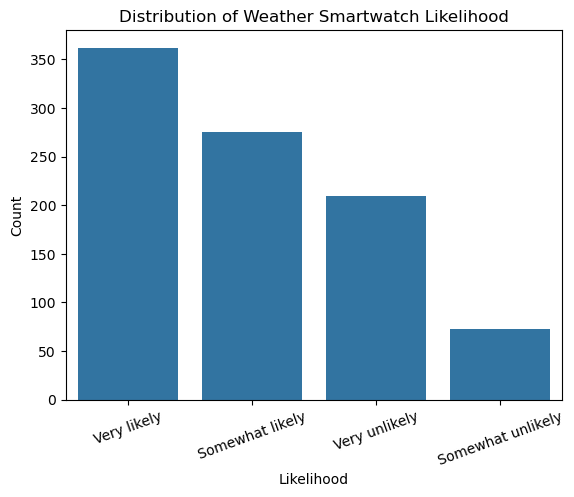

In [11]:
sns.countplot(data=df, x='Weather_Smartwatch_Likelihood')

plt.title("Distribution of Weather Smartwatch Likelihood")
plt.xlabel("Likelihood")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()

In [12]:
df.columns

Index(['RespondentID', 'Check_Weather_Daily', 'Check_Weather_Method',
       'Weather_Smartwatch_Likelihood', 'Age', 'Gender', 'Household_Income',
       'US Region'],
      dtype='object')

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 919 entries, 0 to 918
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   RespondentID                   919 non-null    int64 
 1   Check_Weather_Daily            919 non-null    object
 2   Check_Weather_Method           919 non-null    object
 3   Weather_Smartwatch_Likelihood  919 non-null    object
 4   Age                            919 non-null    object
 5   Gender                         919 non-null    object
 6   Household_Income               919 non-null    object
 7   US Region                      919 non-null    object
dtypes: int64(1), object(7)
memory usage: 57.6+ KB


In [14]:
df.describe()

,RespondentID
count,9.190000e+02
mean,3.879084e+09
std,2.445434e+06
min,3.877567e+09
25%,3.877793e+09
50%,3.878059e+09
75%,3.878700e+09
max,3.887201e+09


In [19]:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers), "outliers")

RespondentID : 156 outliers


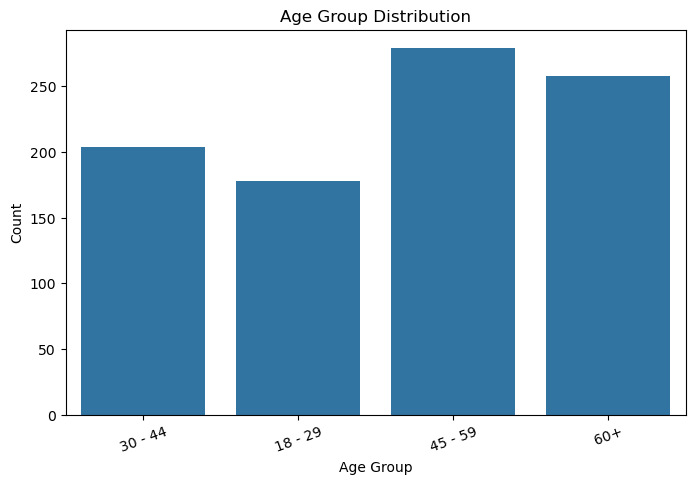

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Age')

plt.title("Age Group Distribution")
plt.xlabel("Age Group")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()